In [1]:
# 1. Load libraries
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from PIL import Image
import h5py

In [2]:
# 2. Necessary function: average the pixels in each bin

def bin_average(coordinates, image, edges, valid):
    pixel_count = np.histogram(coordinates[valid], bins=edges)[0]
    total = np.histogram(coordinates[valid], bins=edges, weights=image[valid])[0]
    average = np.full(len(edges) - 1, np.nan)
    np.divide(total, pixel_count, out=average, where=pixel_count > 0)
    return average, total, pixel_count

def load_detector_image(path, dataset_path=None):
    """Load MCP text, SEXTANTS NeXus, or a detector TIFF image."""
    if path.suffix.lower() == ".txt":
        return np.loadtxt(path)
    if path.suffix.lower() in (".tif", ".tiff"):
        with Image.open(path) as file:
            return np.asarray(file, dtype=float)

    with h5py.File(path, "r") as file:
        if dataset_path is None:
            # SEXTANTS channel numbers change: identify image channels by metadata.
            candidates = []
            for entry in file.values():
                if isinstance(entry, h5py.Group) and "scan_data" in entry:
                    for dataset in entry["scan_data"].values():
                        if isinstance(dataset, h5py.Dataset) and dataset.ndim >= 2:
                            description = str(dataset.attrs.get("interpretation", "")) + str(dataset.attrs.get("long_name", ""))
                            if "image" in description.lower():
                                candidates.append(dataset)
            dataset = max(candidates, key=lambda d: np.prod(d.shape[-2:]))
        else:
            dataset = file[dataset_path]
        print(path.name, "→", dataset.name, dataset.shape)
        image = np.asarray(dataset[()], dtype=float)
    # Multiple exposures in a scan are averaged before combining scans.
    return image.reshape((-1, *image.shape[-2:])).mean(axis=0)


In [3]:
# 3. Input and output folders (relative to this notebook)
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp_analysis")
output_folder.mkdir(parents=True, exist_ok=True)

# "mcp": integers are zero-based file indices.
# "sextants": integers are scan numbers, e.g. 426 -> scanx_0426.nxs.
input_type = "mcp"
# For CCD/CMOS NeXus, change input_folder above to the beamtime raw folder:
# input_folder = Path("../COMET_20260902_Cocoons_Laser_raw")
# input_type = "sextants"
nexus_pattern = "scanx_{id:04d}.nxs"
dataset_path = None              # auto-detect; or e.g. "scan_0426/scan_data/data_22"

file_pattern = "*_TDC_2D_*.txt" if input_type == "mcp" else "*.nxs"
available_images = sorted(input_folder.glob(file_pattern))
for index, path in enumerate(available_images):
    print(index, path.name)

0 26-06-09_00267_TDC_2D_chopper_Zone01.txt
1 26-06-09_00267_TDC_2D_chopper_Zone02.txt
2 26-06-09_00267_TDC_2D_chopper_Zone03.txt
3 26-06-09_00267_TDC_2D_chopper_Zone04.txt
4 26-06-09_00267_TDC_2D_chopper_Zone05.txt
5 26-06-09_00267_TDC_2D_chopper_Zone06.txt


In [4]:
# 4. Each entry gives one image and one pair of average profiles.
# A nested list gives the pixel-by-pixel arithmetic mean of those images.
image_list = [
    ["26-06-09_00267_TDC_2D_chopper_Zone01.txt",
     "26-06-09_00267_TDC_2D_chopper_Zone02.txt"],
    "26-06-09_00267_TDC_2D_chopper_Zone03.txt",
    "26-06-09_00267_TDC_2D_chopper_Zone04.txt",
    "26-06-09_00267_TDC_2D_chopper_Zone05.txt",
    "26-06-09_00267_TDC_2D_chopper_Zone06.txt",
]
# Alternatively, use zero-based indices from cell 3:
# image_list = [[0, 1], 2, 3, 4, 5]
# SEXTANTS scan numbers: image_list = [[426, 427], 432]

In [5]:
# 5. Load images, averaging each nested group before further analysis
image_paths = []                 # output filenames
image_labels = []                # plot labels
image_sources = []               # original files in each group
images = []
for group_index, item in enumerate(image_list):
    group = item if isinstance(item, list) else [item]
    paths = []
    group_images = []
    for member in group:
        if isinstance(member, (int, np.integer)):
            path = (input_folder / nexus_pattern.format(id=member)
                    if input_type == "sextants" else available_images[member])
        else:
            path = input_folder / member
        paths.append(path)
        group_images.append(load_detector_image(path, dataset_path))

    image = np.mean(group_images, axis=0)
    label = " + ".join(path.stem.split("TDC_2D_")[-1] for path in paths)
    output_path = paths[0]
    if len(paths) > 1:
        label = "Mean: " + label
        output_path = paths[0].with_stem(paths[0].stem + f"_mean_group_{group_index:02d}")
    images.append(image)
    image_paths.append(output_path)
    image_labels.append(label)
    image_sources.append([path.name for path in paths])
    print(f"{label}: {image.shape}, total counts = {np.nansum(image):g}")

height, width = images[0].shape

Mean: chopper_Zone01 + chopper_Zone02: (2000, 2400), total counts = 25416
chopper_Zone03: (2000, 2400), total counts = 818
chopper_Zone04: (2000, 2400), total counts = 887
chopper_Zone05: (2000, 2400), total counts = 830
chopper_Zone06: (2000, 2400), total counts = 162042


In [6]:
# 6. Parameters — edit these, then rerun cells 7–10
center_x = (width - 1) / 2        # column coordinate, in original pixels
center_y = (height - 1) / 2       # row coordinate, in original pixels
radial_bin_width = 10.0          # pixels
angular_bin_width = 5.0          # degrees; must divide 360

# Default: largest circle entirely inside the image.
# Set these radii explicitly if you want a different range or an annulus.
radial_max = min(center_x, center_y, width - 1 - center_x, height - 1 - center_y)
annulus_inner = 0.0              # azimuthal average: inner radius in pixels
annulus_outer = radial_max       # azimuthal average: outer radius in pixels

# Optional Paint mask (same pixel dimensions as the detector images).
# Cell 10 saves paint_template.png. Open it in Paint, cover the beamstop
# with RED, then save as beamstop_mask.png (PNG, without resizing).
# Set the path below and rerun cells 6–10. None means no mask.
mask_path = None                 # e.g. output_folder / "beamstop_mask.png"

bad_pixel_mask = np.zeros((height, width), dtype=bool)
if mask_path is not None:
    with Image.open(mask_path) as mask_file:
        rgba = np.asarray(mask_file.convert("RGBA"))
    red = (rgba[:, :, 0] >= 200) & (rgba[:, :, 1] < 100) & (rgba[:, :, 2] < 100)
    red &= rgba[:, :, 3] > 0
    # Paint rows run top-to-bottom; the detector plot has origin="lower".
    bad_pixel_mask = np.flipud(red)
print("Masked pixels:", bad_pixel_mask.sum())

# Image display only; calculations always use original pixels.
display_bin_size = 10            # must divide image dimensions; use 1 for original pixels
# Manual color limits; used exactly as entered.
mi = 0.0
ma = 1.0

Masked pixels: 0


In [7]:
# 7. Calculate radial and azimuthal averages
# Radial: average over angle, plotted versus radius.
# Azimuthal: average within the annulus, plotted versus angle.
# Angle is CCW from +x when images are displayed with origin="lower".
number_of_angles = round(360 / angular_bin_width)

y, x = np.indices((height, width))
radius = np.hypot(x - center_x, y - center_y)
angle = np.degrees(np.arctan2(y - center_y, x - center_x)) % 360
radial_edges = np.append(np.arange(0, radial_max, radial_bin_width), radial_max)
angular_edges = np.linspace(0, 360, number_of_angles + 1)
radial_centers = (radial_edges[:-1] + radial_edges[1:]) / 2
angular_centers = (angular_edges[:-1] + angular_edges[1:]) / 2

radial_profiles = []
azimuthal_profiles = []
radial_totals, radial_pixel_counts = [], []
azimuthal_totals, azimuthal_pixel_counts = [], []
for image in images:
    valid = np.isfinite(image) & ~bad_pixel_mask
    radial_valid = valid & (radius <= radial_max)
    angular_valid = valid & (radius >= annulus_inner) & (radius < annulus_outer)
    average, total, count = bin_average(radius, image, radial_edges, radial_valid)
    radial_profiles.append(average)
    radial_totals.append(total)
    radial_pixel_counts.append(count)
    average, total, count = bin_average(angle, image, angular_edges, angular_valid)
    azimuthal_profiles.append(average)
    azimuthal_totals.append(total)
    azimuthal_pixel_counts.append(count)

print("Calculated profiles for", len(images), "images. Empty bins are NaN.")

Calculated profiles for 5 images. Empty bins are NaN.


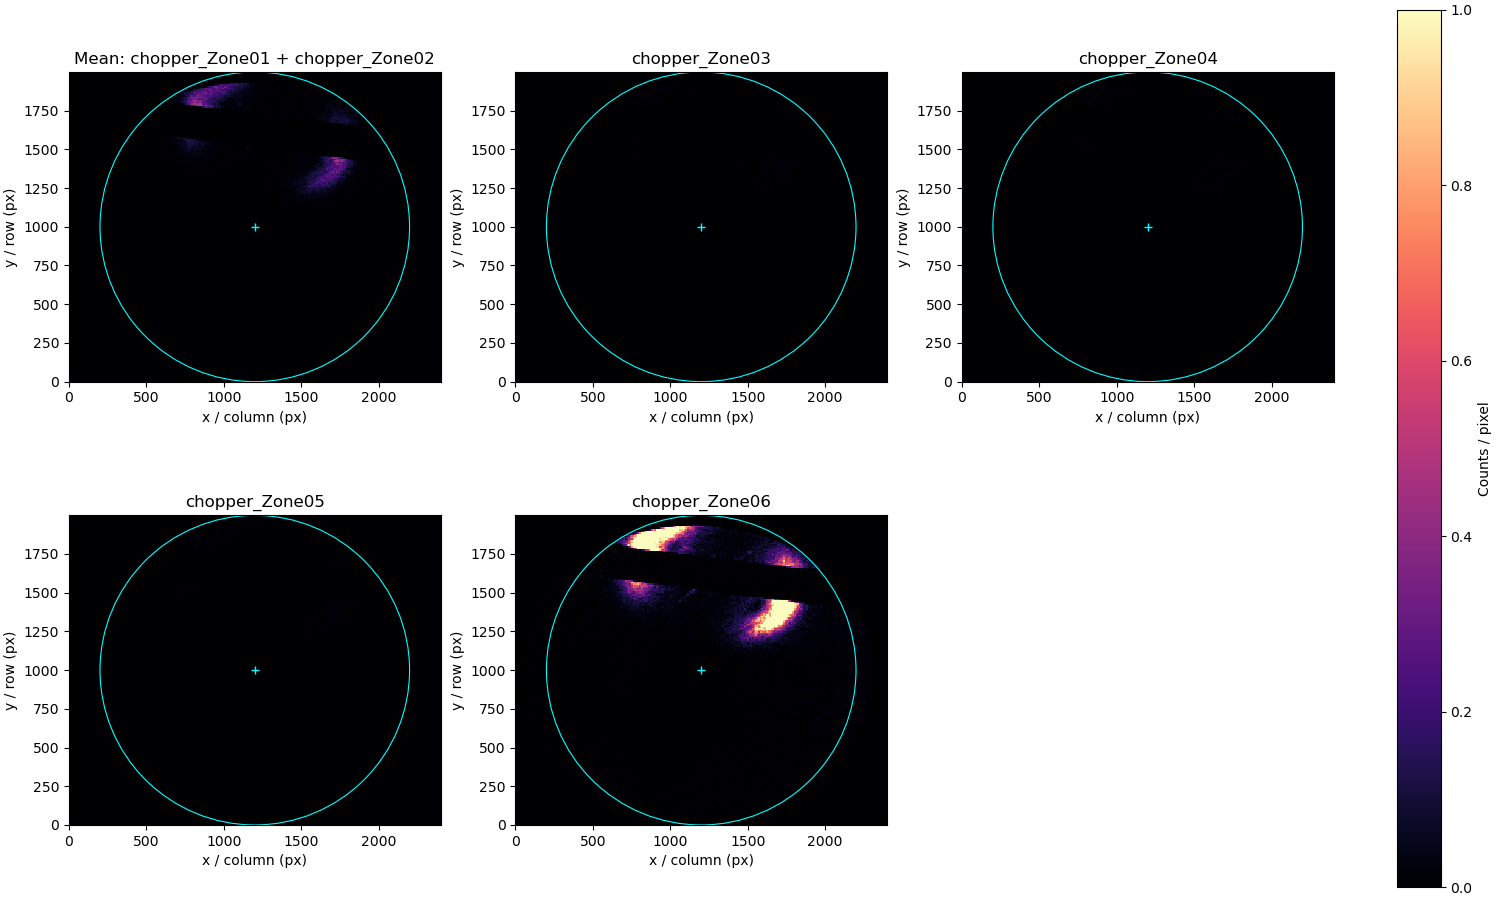

In [8]:
# 8. Plot detector images
# Block averages are for display only, in counts per original pixel.
b = display_bin_size if height % display_bin_size == 0 and width % display_bin_size == 0 else 1
display_images = []
for image in images:
    valid = np.isfinite(image) & ~bad_pixel_mask
    total = np.where(valid, image, 0).reshape(height // b, b, width // b, b).sum(axis=(1, 3))
    count = valid.reshape(height // b, b, width // b, b).sum(axis=(1, 3))
    shown = np.full(total.shape, np.nan)
    np.divide(total, count, out=shown, where=count > 0)
    display_images.append(shown)

# Masked pixels are gray; they do not contribute to block means or color limits.
detector_cmap = plt.get_cmap("magma").copy()
detector_cmap.set_bad("lightgray")

columns = min(3, len(images))
rows = (len(images) + columns - 1) // columns
image_figure, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4.5 * rows),
                                 squeeze=False, constrained_layout=True)
for ax in axes.flat:
    ax.set_visible(False)
for ax, shown, label in zip(axes.flat, display_images, image_labels):
    ax.set_visible(True)
    artist = ax.imshow(shown, origin="lower", cmap=detector_cmap, vmin=mi, vmax=ma,
                       extent=(-0.5, width - 0.5, -0.5, height - 0.5), interpolation="nearest")
    ax.plot(center_x, center_y, "+", color="cyan")
    for r in (annulus_inner, annulus_outer):
        if r > 0:
            ax.add_patch(Circle((center_x, center_y), r, fill=False, color="cyan", linewidth=0.8))
    ax.set(title=label, xlabel="x / column (px)", ylabel="y / row (px)")
image_figure.colorbar(artist, ax=[ax for ax in axes.flat if ax.get_visible()], label="Counts / pixel")
plt.show()

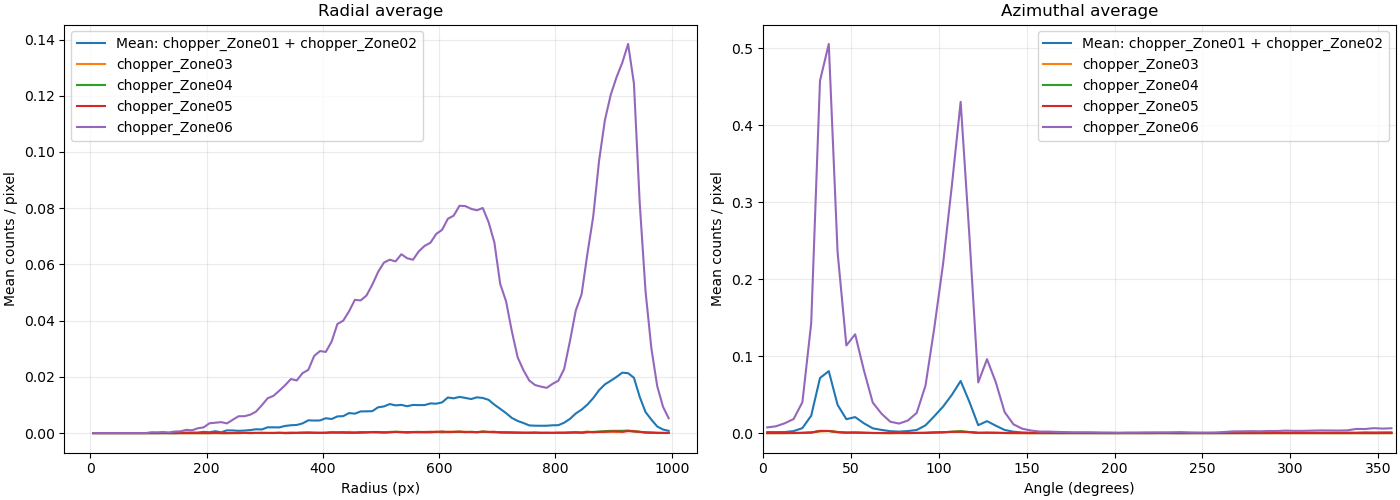

In [9]:
# 9. Plot the radial and azimuthal averages
profile_figure, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, radial, azimuthal in zip(image_labels, radial_profiles, azimuthal_profiles):
    axes[0].plot(radial_centers, radial, label=label)
    axes[1].plot(angular_centers, azimuthal, label=label)
axes[0].set(title="Radial average", xlabel="Radius (px)", ylabel="Mean counts / pixel")
axes[1].set(title="Azimuthal average", xlabel="Angle (degrees)", ylabel="Mean counts / pixel", xlim=(0, 360))
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

In [10]:
# 10. Save figures, profiles and parameters
output_folder.mkdir(parents=True, exist_ok=True)
image_figure.savefig(output_folder / "mcp_images.png", dpi=150)
profile_figure.savefig(output_folder / "mcp_profiles.png", dpi=150)

for i, path in enumerate(image_paths):
    radial_table = np.column_stack((radial_edges[:-1], radial_edges[1:], radial_centers,
                                   radial_profiles[i], radial_totals[i], radial_pixel_counts[i]))
    angular_table = np.column_stack((angular_edges[:-1], angular_edges[1:], angular_centers,
                                    azimuthal_profiles[i], azimuthal_totals[i], azimuthal_pixel_counts[i]))
    np.savetxt(output_folder / f"{path.stem}_radial.csv", radial_table, delimiter=",", comments="",
               header="bin_start_px,bin_end_px,radius_px,mean_counts_per_pixel,sum_counts,valid_pixels")
    np.savetxt(output_folder / f"{path.stem}_azimuthal.csv", angular_table, delimiter=",", comments="",
               header="bin_start_deg,bin_end_deg,angle_deg,mean_counts_per_pixel,sum_counts,valid_pixels")

parameters = dict(center_x=float(center_x), center_y=float(center_y),
                  radial_bin_width=radial_bin_width, radial_max=radial_max,
                  angular_bin_width=angular_bin_width,
                  annulus_inner=annulus_inner, annulus_outer=annulus_outer,
                  display_bin_size=display_bin_size, mi=mi, ma=ma,
                  input_type=input_type, dataset_path=dataset_path,
                  mask_path=str(mask_path) if mask_path is not None else None,
                  images=image_sources,
                  group_operation="pixel-by-pixel arithmetic mean",
                  angle_convention="CCW from +x with origin lower",
                  normalization="raw counts per valid pixel; no time normalization")
(output_folder / "settings.json").write_text(json.dumps(parameters, indent=2) + "\n")
np.save(output_folder / "excluded_pixels.npy", bad_pixel_mask)
print("Saved to", output_folder.resolve())

# Unbinned grayscale template: same orientation as the plotted images.
# Use this in Paint so red annotations line up exactly with detector pixels.
# Existing templates are kept so rerunning does not overwrite your work.
template_path = output_folder / "paint_template.png"
if not template_path.exists():
    template = np.nan_to_num(images[0], nan=0, posinf=0, neginf=0)
    template = np.clip(template / max(float(template.max()), 1), 0, 1)
    template = np.uint8(255 * template)
    Image.fromarray(np.flipud(template)).convert("RGB").save(template_path)


Saved to /Users/riccardo/Github/SEXTANTS_261105/output/mcp_analysis
